In [1]:

# =====================================================
# CAMPUSOPTI AI - TIMETABLE OPTIMISATION
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import defaultdict

# Load datasets

faculty = pd.read_csv("../dataset/faculty.csv")
classrooms = pd.read_csv("../dataset/classrooms.csv")
batches = pd.read_csv("../dataset/student_batches.csv")
subjects = pd.read_csv("../dataset/subjects.csv")

time_slots = pd.read_csv("../dataset/time_slots.csv")

batch_subjects = pd.read_csv("../dataset/batch_subjects.csv")
faculty_subjects = pd.read_csv("../dataset/faculty_subjects.csv")
faculty_availability = pd.read_csv("../dataset/faculty_availability.csv")

print("All scheduling datasets loaded!")


All scheduling datasets loaded!


In [2]:

# =====================================================
# SCHEDULING DATA VALIDATION
# =====================================================

scheduling_data = batch_subjects.merge(
    batches[["batch_id", "student_count"]],
    on="batch_id",
    how="left"
)

scheduling_data = scheduling_data.merge(
    subjects[["subject_id", "subject_name"]],
    on="subject_id",
    how="left"
)

scheduling_data["compatible_rooms"] = (
    scheduling_data["required_room_type"].map(
        classrooms.groupby("room_type")["capacity"]
        .apply(lambda x: (x >= 0).sum())
    )
)

# Actual room compatibility by capacity

def get_compatible_rooms(row):

    return classrooms[
        (classrooms["room_type"] == row["required_room_type"]) &
        (classrooms["capacity"] >= row["student_count"])
    ]["room_id"].tolist()

scheduling_data["compatible_rooms"] = scheduling_data.apply(
    get_compatible_rooms,
    axis=1
)

scheduling_data["room_available"] = (
    scheduling_data["compatible_rooms"].apply(len) > 0
)

print("Scheduling requirements:", len(scheduling_data))
print("Requirements without compatible rooms:",
      (~scheduling_data["room_available"]).sum())

display(scheduling_data.head())


Scheduling requirements: 48
Requirements without compatible rooms: 5


,batch_id,subject_id,faculty_id,lectures_per_week,required_room_type,student_count,subject_name,compatible_rooms,room_available
0,B001,S010,F010,3,Lab,67,Web Technology,[],False
1,B001,S008,F008,3,Classroom,67,Operating Systems,"[R002, R006]",True
2,B001,S012,F012,4,Classroom,67,Software Engineering,"[R002, R006]",True
3,B001,S015,F015,3,Classroom,67,Cyber Security,"[R002, R006]",True
4,B001,S003,F003,2,Classroom,67,DBMS,"[R002, R006]",True


In [3]:

# =====================================================
# WEEKLY LECTURE REQUIREMENTS
# =====================================================

total_lectures = scheduling_data["lectures_per_week"].sum()

available_slots = len(time_slots)

print("Total required lectures:", total_lectures)
print("Available weekly time slots:", available_slots)

print("\nTotal classrooms:", len(classrooms))
print("Total faculty:", len(faculty))
print("Total batches:", len(batches))


Total required lectures: 142
Available weekly time slots: 30

Total classrooms: 14
Total faculty: 20
Total batches: 8


In [4]:

# =====================================================
# CAMPUSOPTI AI - INDIVIDUAL LECTURE GENERATION
# =====================================================

lecture_tasks = []

for _, row in scheduling_data.iterrows():

    for lecture_no in range(int(row["lectures_per_week"])):

        lecture_tasks.append({
            "batch_id": row["batch_id"],
            "subject_id": row["subject_id"],
            "subject_name": row["subject_name"],
            "faculty_id": row["faculty_id"],
            "student_count": row["student_count"],
            "room_type": row["required_room_type"],
            "lecture_no": lecture_no + 1
        })

lecture_tasks = pd.DataFrame(lecture_tasks)

print("Individual Lecture Tasks Created!")
print("Total Lecture Tasks:", len(lecture_tasks))

display(lecture_tasks.head(10))


Individual Lecture Tasks Created!
Total Lecture Tasks: 142


,batch_id,subject_id,subject_name,faculty_id,student_count,room_type,lecture_no
0,B001,S010,Web Technology,F010,67,Lab,1
1,B001,S010,Web Technology,F010,67,Lab,2
2,B001,S010,Web Technology,F010,67,Lab,3
3,B001,S008,Operating Systems,F008,67,Classroom,1
4,B001,S008,Operating Systems,F008,67,Classroom,2
5,B001,S008,Operating Systems,F008,67,Classroom,3
6,B001,S012,Software Engineering,F012,67,Classroom,1
7,B001,S012,Software Engineering,F012,67,Classroom,2
8,B001,S012,Software Engineering,F012,67,Classroom,3
9,B001,S012,Software Engineering,F012,67,Classroom,4


In [5]:

# =====================================================
# SCHEDULING FEASIBILITY CHECK
# =====================================================

room_counts = []

for _, task in lecture_tasks.iterrows():

    compatible = classrooms[
        (classrooms["room_type"] == task["room_type"]) &
        (classrooms["capacity"] >= task["student_count"])
    ]

    room_counts.append(len(compatible))

lecture_tasks["compatible_room_count"] = room_counts

print("Lectures without compatible rooms:",
      (lecture_tasks["compatible_room_count"] == 0).sum())

batch_demand = lecture_tasks.groupby("batch_id").size()

print("\nWeekly demand per batch:")
print(batch_demand)

print("\nMaximum available slots per batch:",
      len(time_slots))


Lectures without compatible rooms: 14

Weekly demand per batch:
batch_id
B001    18
B002    18
B003    16
B004    20
B005    16
B006    19
B007    19
B008    16
dtype: int64

Maximum available slots per batch: 30


In [6]:

# =====================================================
# CAMPUSOPTI AI - GREEDY TIMETABLE GENERATION
# =====================================================

import time

start_time = time.time()

schedule = []

used_rooms = set()
used_faculty = set()
used_batches = set()

faculty_daily_load = defaultdict(int)

# Sort difficult lectures first
lecture_tasks_sorted = lecture_tasks.sort_values(
    by=["compatible_room_count", "student_count"],
    ascending=[True, False]
)

# Convert faculty availability into a lookup
availability_lookup = {
    (row["faculty_id"], row["slot_id"]): row["available"]
    for _, row in faculty_availability.iterrows()
}

for _, task in lecture_tasks_sorted.iterrows():

    assigned = False

    for _, slot in time_slots.iterrows():

        slot_id = slot["slot_id"]
        day = slot["day"]

        # Check batch conflict
        if (task["batch_id"], slot_id) in used_batches:
            continue

        # Check faculty conflict
        if (task["faculty_id"], slot_id) in used_faculty:
            continue

        # Check faculty availability
        if availability_lookup.get(
            (task["faculty_id"], slot_id), 0
        ) != 1:
            continue

        # Check faculty daily workload
        max_load = faculty.loc[
            faculty["faculty_id"] == task["faculty_id"],
            "max_lectures_per_day"
        ].iloc[0]

        if faculty_daily_load.get(
            (task["faculty_id"], day), 0
        ) >= max_load:
            continue

        # Find compatible classrooms
        compatible_rooms = classrooms[
            (classrooms["room_type"] == task["room_type"]) &
            (classrooms["capacity"] >= task["student_count"])
        ]

        for _, room in compatible_rooms.iterrows():

            room_id = room["room_id"]

            # Check room conflict
            if (room_id, slot_id) in used_rooms:
                continue

            # Allocate lecture
            schedule.append({
                "batch_id": task["batch_id"],
                "subject_id": task["subject_id"],
                "subject_name": task["subject_name"],
                "faculty_id": task["faculty_id"],
                "room_id": room_id,
                "slot_id": slot_id,
                "day": day,
                "time": slot["time"]
            })

            used_rooms.add((room_id, slot_id))
            used_faculty.add((task["faculty_id"], slot_id))
            used_batches.add((task["batch_id"], slot_id))

            faculty_daily_load[
                (task["faculty_id"], day)
            ] += 1

            assigned = True
            break

        if assigned:
            break

greedy_schedule = pd.DataFrame(schedule)

execution_time = time.time() - start_time

print("Greedy Scheduling Completed!")
print("Scheduled Lectures:", len(greedy_schedule))
print("Unscheduled Lectures:",
      len(lecture_tasks) - len(greedy_schedule))
print("Execution Time:", round(execution_time, 4), "seconds")

display(greedy_schedule.head(15))


Greedy Scheduling Completed!
Scheduled Lectures: 125
Unscheduled Lectures: 17
Execution Time: 3.6767 seconds


,batch_id,subject_id,subject_name,faculty_id,room_id,slot_id,day,time
0,B006,S008,Operating Systems,F008,R002,T01,Monday,09:00-10:00
1,B006,S008,Operating Systems,F008,R002,T02,Monday,10:00-11:00
2,B006,S008,Operating Systems,F008,R002,T03,Monday,11:15-12:15
3,B006,S014,Data Mining,F014,R002,T05,Monday,14:00-15:00
4,B006,S014,Data Mining,F014,R002,T06,Monday,15:00-16:00
5,B006,S014,Data Mining,F014,R002,T07,Tuesday,09:00-10:00
6,B006,S006,Artificial Intelligence,F006,R002,T04,Monday,12:15-13:15
7,B006,S006,Artificial Intelligence,F006,R002,T08,Tuesday,10:00-11:00
8,B006,S006,Artificial Intelligence,F006,R002,T09,Tuesday,11:15-12:15
9,B006,S012,Software Engineering,F012,R002,T10,Tuesday,12:15-13:15


In [7]:

# =====================================================
# GREEDY ALGORITHM EVALUATION
# =====================================================

total_required = len(lecture_tasks)
scheduled = len(greedy_schedule)
unscheduled = total_required - scheduled

scheduling_percentage = (
    scheduled / total_required
) * 100 if total_required else 0

# Room utilisation
total_room_slots = len(classrooms) * len(time_slots)

room_utilisation = (
    len(greedy_schedule) / total_room_slots
) * 100 if total_room_slots else 0

print("GREEDY ALGORITHM PERFORMANCE")
print("=" * 40)

print("Total Required:", total_required)
print("Scheduled:", scheduled)
print("Unscheduled:", unscheduled)

print("Scheduling Percentage:",
      round(scheduling_percentage, 2), "%")

print("Room Utilisation:",
      round(room_utilisation, 2), "%")

print("Execution Time:",
      round(execution_time, 4), "seconds")


GREEDY ALGORITHM PERFORMANCE
Total Required: 142
Scheduled: 125
Unscheduled: 17
Scheduling Percentage: 88.03 %
Room Utilisation: 29.76 %
Execution Time: 3.6767 seconds


In [8]:
greedy_schedule.to_csv(
    "../reports/greedy_timetable.csv",
    index=False
)

print("Greedy timetable saved successfully!")

Greedy timetable saved successfully!


In [9]:
print("GREEDY ALGORITHM RESULTS")
print("=" * 40)

print("Total Required:", total_required)
print("Scheduled:", scheduled)
print("Unscheduled:", unscheduled)
print("Scheduling Percentage:", round(scheduling_percentage, 2), "%")
print("Room Utilisation:", round(room_utilisation, 2), "%")
print("Execution Time:", round(execution_time, 4), "seconds")

GREEDY ALGORITHM RESULTS
Total Required: 142
Scheduled: 125
Unscheduled: 17
Scheduling Percentage: 88.03 %
Room Utilisation: 29.76 %
Execution Time: 3.6767 seconds


In [10]:
# Count required lectures for each batch and subject
required_counts = (
    lecture_tasks
    .groupby(["batch_id", "subject_id"])
    .size()
    .reset_index(name="required")
)

# Count successfully scheduled lectures
scheduled_counts = (
    greedy_schedule
    .groupby(["batch_id", "subject_id"])
    .size()
    .reset_index(name="scheduled")
)

# Compare required and scheduled lectures
unscheduled_report = required_counts.merge(
    scheduled_counts,
    on=["batch_id", "subject_id"],
    how="left"
)

unscheduled_report["scheduled"] = (
    unscheduled_report["scheduled"].fillna(0).astype(int)
)

unscheduled_report["remaining"] = (
    unscheduled_report["required"] -
    unscheduled_report["scheduled"]
)

# Display only unscheduled lecture requirements
unscheduled_report = unscheduled_report[
    unscheduled_report["remaining"] > 0
]

print("UNSCHEDULED LECTURE DETAILS")
print("=" * 50)

print(unscheduled_report.to_string(index=False))

print("\nTotal unscheduled lectures:",
      unscheduled_report["remaining"].sum())

UNSCHEDULED LECTURE DETAILS
batch_id subject_id  required  scheduled  remaining
    B001       S010         3          0          3
    B003       S010         3          0          3
    B003       S011         2          0          2
    B004       S008         3          0          3
    B006       S010         3          0          3
    B006       S013         3          0          3

Total unscheduled lectures: 17


In [13]:
print("Scheduling Data Columns:")
print(scheduling_data.columns.tolist())

print("\nSubject Data Columns:")
print(subjects.columns.tolist())

print("\nBatch Subject Data Columns:")
print(batch_subjects.columns.tolist())

Scheduling Data Columns:
['batch_id', 'subject_id', 'faculty_id', 'lectures_per_week', 'required_room_type', 'student_count', 'subject_name', 'compatible_rooms', 'room_available']

Subject Data Columns:
['subject_id', 'subject_name', 'required_lectures_per_week', 'required_room_type']

Batch Subject Data Columns:
['batch_id', 'subject_id', 'faculty_id', 'lectures_per_week', 'required_room_type']


In [15]:
print("Faculty Availability Columns:")
print(faculty_availability.columns.tolist())

print("\nFirst 5 Rows:")
display(faculty_availability.head())

Faculty Availability Columns:
['faculty_id', 'slot_id', 'available']

First 5 Rows:


,faculty_id,slot_id,available
0,F001,T01,1
1,F001,T02,0
2,F001,T03,1
3,F001,T04,1
4,F001,T05,1


In [16]:
# Get details of affected batch-subject combinations
diagnosis = unscheduled_report.merge(
    scheduling_data[
        [
            "batch_id",
            "subject_id",
            "faculty_id",
            "student_count",
            "required_room_type"
        ]
    ].drop_duplicates(),
    on=["batch_id", "subject_id"],
    how="left"
)

# Count available slots for each faculty member
availability_count = (
    faculty_availability[
        faculty_availability["available"] == 1
    ]
    .groupby("faculty_id")
    .size()
)

diagnosis["faculty_available_slots"] = (
    diagnosis["faculty_id"]
    .map(availability_count)
    .fillna(0)
    .astype(int)
)

# Count compatible classrooms
def count_compatible_rooms(row):
    compatible = classrooms[
        (classrooms["room_type"] == row["required_room_type"]) &
        (classrooms["capacity"] >= row["student_count"])
    ]
    return len(compatible)

diagnosis["compatible_rooms"] = diagnosis.apply(
    count_compatible_rooms,
    axis=1
)

# Get faculty daily teaching limits
diagnosis = diagnosis.merge(
    faculty[["faculty_id", "max_lectures_per_day"]],
    on="faculty_id",
    how="left"
)

# Display diagnosis
print("RESOURCE BOTTLENECK DIAGNOSIS")
print("=" * 65)

print(
    diagnosis[
        [
            "batch_id",
            "subject_id",
            "faculty_id",
            "remaining",
            "faculty_available_slots",
            "compatible_rooms",
            "max_lectures_per_day"
        ]
    ].to_string(index=False)
)

RESOURCE BOTTLENECK DIAGNOSIS
batch_id subject_id faculty_id  remaining  faculty_available_slots  compatible_rooms  max_lectures_per_day
    B001       S010       F010          3                       25                 0                     4
    B003       S010       F010          3                       25                 0                     4
    B003       S011       F011          2                       27                 0                     3
    B004       S008       F008          3                       27                 8                     3
    B006       S010       F010          3                       25                 0                     4
    B006       S013       F013          3                       23                 0                     3


In [17]:
print("AFFECTED LECTURE REQUIREMENTS")
print("=" * 60)

print(
    diagnosis[
        [
            "batch_id",
            "subject_id",
            "student_count",
            "required_room_type",
            "compatible_rooms"
        ]
    ].to_string(index=False)
)

print("\nAVAILABLE CLASSROOMS")
print("=" * 60)

print(
    classrooms.groupby("room_type").agg(
        total_rooms=("room_id", "count"),
        minimum_capacity=("capacity", "min"),
        maximum_capacity=("capacity", "max")
    )
)

AFFECTED LECTURE REQUIREMENTS
batch_id subject_id  student_count required_room_type  compatible_rooms
    B001       S010             67                Lab                 0
    B003       S010             67                Lab                 0
    B003       S011             67                Lab                 0
    B004       S008             46          Classroom                 8
    B006       S010             68                Lab                 0
    B006       S013             68                Lab                 0

AVAILABLE CLASSROOMS
           total_rooms  minimum_capacity  maximum_capacity
room_type                                                 
Classroom           10                42                78
Lab                  4                41                65


In [18]:
print("CURRENT LAB DETAILS")
print("=" * 40)

lab_rooms = classrooms[
    classrooms["room_type"] == "Lab"
].copy()

print(lab_rooms.to_string(index=False))

print("\nLargest student batch:",
      batches["student_count"].max())

CURRENT LAB DETAILS
room_id room_type  capacity
   R011       Lab        48
   R012       Lab        65
   R013       Lab        41
   R014       Lab        59

Largest student batch: 68


In [19]:
# Update synthetic lab capacities
lab_capacity_updates = {
    "R011": 70,
    "R012": 75,
    "R013": 50,
    "R014": 65
}

classrooms["capacity"] = classrooms.apply(
    lambda row: lab_capacity_updates.get(
        row["room_id"], row["capacity"]
    ),
    axis=1
)

# Display updated labs
updated_labs = classrooms[
    classrooms["room_type"] == "Lab"
]

print("UPDATED LAB CAPACITIES")
print(updated_labs.to_string(index=False))

# Save updated classroom dataset
classrooms.to_csv(
    "../dataset/classrooms.csv",
    index=False
)

UPDATED LAB CAPACITIES
room_id room_type  capacity
   R011       Lab        70
   R012       Lab        75
   R013       Lab        50
   R014       Lab        65


In [20]:
# Recalculate compatible room counts
diagnosis["compatible_rooms"] = diagnosis.apply(
    lambda row: len(
        classrooms[
            (classrooms["room_type"] == row["required_room_type"]) &
            (classrooms["capacity"] >= row["student_count"])
        ]
    ),
    axis=1
)

print("UPDATED ROOM COMPATIBILITY")
print("=" * 50)

print(
    diagnosis[
        [
            "batch_id",
            "subject_id",
            "student_count",
            "required_room_type",
            "compatible_rooms"
        ]
    ].to_string(index=False)
)

print(
    "\nCombinations without compatible rooms:",
    (diagnosis["compatible_rooms"] == 0).sum()
)

UPDATED ROOM COMPATIBILITY
batch_id subject_id  student_count required_room_type  compatible_rooms
    B001       S010             67                Lab                 2
    B003       S010             67                Lab                 2
    B003       S011             67                Lab                 2
    B004       S008             46          Classroom                 8
    B006       S010             68                Lab                 2
    B006       S013             68                Lab                 2

Combinations without compatible rooms: 0


In [23]:
# Rebuild lecture tasks from scheduling_data

lecture_task_list = []

for _, row in scheduling_data.iterrows():

    for i in range(int(row["lectures_per_week"])):

        lecture_task_list.append({
            "batch_id": row["batch_id"],
            "subject_id": row["subject_id"],
            "subject_name": row["subject_name"],
            "faculty_id": row["faculty_id"],
            "student_count": row["student_count"],
            "room_type": row["required_room_type"],
            "lecture_no": i + 1
        })

lecture_tasks = pd.DataFrame(lecture_task_list)

# Calculate compatible classrooms using updated capacities

lecture_tasks["compatible_room_count"] = lecture_tasks.apply(
    lambda task: len(
        classrooms[
            (classrooms["room_type"] == task["room_type"]) &
            (classrooms["capacity"] >= task["student_count"])
        ]
    ),
    axis=1
)

print("LECTURE TASKS REBUILT")
print("=" * 40)

print("Total lecture tasks:", len(lecture_tasks))
print("Columns:", lecture_tasks.columns.tolist())

print(
    "Lectures without compatible rooms:",
    (lecture_tasks["compatible_room_count"] == 0).sum()
)

display(lecture_tasks.head())

LECTURE TASKS REBUILT
Total lecture tasks: 142
Columns: ['batch_id', 'subject_id', 'subject_name', 'faculty_id', 'student_count', 'room_type', 'lecture_no', 'compatible_room_count']
Lectures without compatible rooms: 0


,batch_id,subject_id,subject_name,faculty_id,student_count,room_type,lecture_no,compatible_room_count
0,B001,S010,Web Technology,F010,67,Lab,1,2
1,B001,S010,Web Technology,F010,67,Lab,2,2
2,B001,S010,Web Technology,F010,67,Lab,3,2
3,B001,S008,Operating Systems,F008,67,Classroom,1,2
4,B001,S008,Operating Systems,F008,67,Classroom,2,2


In [24]:
import time
from collections import defaultdict

# Reset scheduling variables
schedule = []
used_rooms = set()
used_faculty = set()
used_batches = set()
faculty_daily_load = defaultdict(int)

# Create availability lookup
availability_lookup = {
    (row.faculty_id, row.slot_id): row.available
    for row in faculty_availability.itertuples()
}

# Create faculty daily limit lookup
faculty_daily_limit = dict(
    zip(faculty["faculty_id"], faculty["max_lectures_per_day"])
)

# Sort difficult lectures first
sorted_tasks = lecture_tasks.sort_values(
    by=["compatible_room_count", "student_count"],
    ascending=[True, False]
)

start_time = time.time()

# Greedy scheduling
for _, task in sorted_tasks.iterrows():

    assigned = False

    for _, slot in time_slots.iterrows():

        faculty_id = task["faculty_id"]
        batch_id = task["batch_id"]
        slot_id = slot["slot_id"]
        day = slot["day"]

        # Check faculty availability
        if availability_lookup.get((faculty_id, slot_id), 0) != 1:
            continue

        # Check batch clash
        if (batch_id, slot_id) in used_batches:
            continue

        # Check faculty clash
        if (faculty_id, slot_id) in used_faculty:
            continue

        # Check daily faculty limit
        if faculty_daily_load[(faculty_id, day)] >= faculty_daily_limit[faculty_id]:
            continue

        # Find compatible rooms
        compatible = classrooms[
            (classrooms["room_type"] == task["room_type"]) &
            (classrooms["capacity"] >= task["student_count"])
        ]

        for _, room in compatible.iterrows():

            room_id = room["room_id"]

            if (room_id, slot_id) in used_rooms:
                continue

            # Assign lecture
            schedule.append({
                "batch_id": batch_id,
                "subject_id": task["subject_id"],
                "subject_name": task["subject_name"],
                "faculty_id": faculty_id,
                "room_id": room_id,
                "slot_id": slot_id,
                "day": day,
                "time": slot["time"]
            })

            used_rooms.add((room_id, slot_id))
            used_faculty.add((faculty_id, slot_id))
            used_batches.add((batch_id, slot_id))

            faculty_daily_load[(faculty_id, day)] += 1

            assigned = True
            break

        if assigned:
            break

# Create timetable
greedy_schedule = pd.DataFrame(schedule)

execution_time = time.time() - start_time

# Evaluate performance
total_required = len(lecture_tasks)
scheduled = len(greedy_schedule)
unscheduled = total_required - scheduled

scheduling_percentage = (
    scheduled / total_required * 100
)

total_room_slots = len(classrooms) * len(time_slots)

room_utilisation = (
    scheduled / total_room_slots * 100
)

# Display results
print("REVISED GREEDY ALGORITHM RESULTS")
print("=" * 45)

print("Total Required:", total_required)
print("Scheduled:", scheduled)
print("Unscheduled:", unscheduled)
print("Scheduling Percentage:", round(scheduling_percentage, 2), "%")
print("Room Utilisation:", round(room_utilisation, 2), "%")
print("Execution Time:", round(execution_time, 4), "seconds")

# Save revised timetable
greedy_schedule.to_csv(
    "../reports/greedy_timetable_revised.csv",
    index=False
)

REVISED GREEDY ALGORITHM RESULTS
Total Required: 142
Scheduled: 139
Unscheduled: 3
Scheduling Percentage: 97.89 %
Room Utilisation: 33.1 %
Execution Time: 1.4534 seconds


In [25]:
# ==========================================
# GREEDY TIMETABLE VALIDATION
# ==========================================

# 1. Check duplicate batch assignments
batch_clashes = greedy_schedule.duplicated(
    ["batch_id", "slot_id"]
).sum()

# 2. Check duplicate faculty assignments
faculty_clashes = greedy_schedule.duplicated(
    ["faculty_id", "slot_id"]
).sum()

# 3. Check duplicate room assignments
room_clashes = greedy_schedule.duplicated(
    ["room_id", "slot_id"]
).sum()

# 4. Check faculty availability
availability_check = greedy_schedule.copy()

availability_check["available"] = availability_check.apply(
    lambda row: availability_lookup.get(
        (row["faculty_id"], row["slot_id"]), 0
    ),
    axis=1
)

unavailable_assignments = (
    availability_check["available"] != 1
).sum()

# 5. Check room type and capacity
room_check = greedy_schedule.merge(
    classrooms[["room_id", "room_type", "capacity"]],
    on="room_id",
    how="left"
)

task_details = lecture_tasks[
    ["batch_id", "subject_id", "student_count", "room_type"]
].drop_duplicates()

room_check = room_check.merge(
    task_details,
    on=["batch_id", "subject_id"],
    how="left"
)

invalid_rooms = (
    (room_check["room_type_x"] != room_check["room_type_y"]) |
    (room_check["capacity"] < room_check["student_count"])
).sum()

# 6. Check faculty daily workload
daily_load = (
    greedy_schedule.groupby(["faculty_id", "day"])
    .size()
    .reset_index(name="daily_lectures")
)

daily_load["maximum_allowed"] = (
    daily_load["faculty_id"].map(faculty_daily_limit)
)

daily_limit_violations = (
    daily_load["daily_lectures"] >
    daily_load["maximum_allowed"]
).sum()

# Display validation results
print("TIMETABLE VALIDATION RESULTS")
print("=" * 45)

print("Batch clashes:", batch_clashes)
print("Faculty clashes:", faculty_clashes)
print("Room clashes:", room_clashes)
print("Faculty availability violations:", unavailable_assignments)
print("Invalid room assignments:", invalid_rooms)
print("Faculty daily limit violations:", daily_limit_violations)

TIMETABLE VALIDATION RESULTS
Batch clashes: 0
Faculty clashes: 0
Room clashes: 0
Faculty availability violations: 0
Invalid room assignments: 0
Faculty daily limit violations: 0


In [26]:
required_counts = (
    lecture_tasks.groupby(["batch_id", "subject_id"])
    .size()
    .reset_index(name="required")
)

scheduled_counts = (
    greedy_schedule.groupby(["batch_id", "subject_id"])
    .size()
    .reset_index(name="scheduled")
)

remaining_report = required_counts.merge(
    scheduled_counts,
    on=["batch_id", "subject_id"],
    how="left"
)

remaining_report["scheduled"] = (
    remaining_report["scheduled"].fillna(0).astype(int)
)

remaining_report["remaining"] = (
    remaining_report["required"] -
    remaining_report["scheduled"]
)

remaining_report = remaining_report[
    remaining_report["remaining"] > 0
]

print("REMAINING UNSCHEDULED LECTURES")
print(remaining_report.to_string(index=False))

print(
    "\nTotal remaining:",
    remaining_report["remaining"].sum()
)

REMAINING UNSCHEDULED LECTURES
batch_id subject_id  required  scheduled  remaining
    B004       S008         3          0          3

Total remaining: 3


In [27]:
# Identify the remaining batch and subject
remaining_task = lecture_tasks[
    (lecture_tasks["batch_id"] == "B004") &
    (lecture_tasks["subject_id"] == "S008")
].iloc[0]

batch_id = remaining_task["batch_id"]
faculty_id = remaining_task["faculty_id"]

print("UNSCHEDULED LECTURE DIAGNOSIS")
print("=" * 45)

print("Batch:", batch_id)
print("Subject:", remaining_task["subject_name"])
print("Faculty:", faculty_id)

# Batch slot availability
batch_used = set(
    greedy_schedule.loc[
        greedy_schedule["batch_id"] == batch_id,
        "slot_id"
    ]
)

print("\nBatch free slots:", len(time_slots) - len(batch_used))

# Faculty availability
faculty_available_slots = faculty_availability[
    (faculty_availability["faculty_id"] == faculty_id) &
    (faculty_availability["available"] == 1)
]

print("Faculty available slots:", len(faculty_available_slots))

# Faculty daily workload
print("\nFaculty daily workload:")

faculty_load = (
    greedy_schedule[
        greedy_schedule["faculty_id"] == faculty_id
    ]
    .groupby("day")
    .size()
)

for day in time_slots["day"].unique():
    limit = faculty_daily_limit[faculty_id]
    load = faculty_load.get(day, 0)
    print(f"{day}: {load}/{limit}")

# Compatible classrooms
compatible_rooms = classrooms[
    (classrooms["room_type"] == remaining_task["room_type"]) &
    (classrooms["capacity"] >= remaining_task["student_count"])
]

print("\nCompatible classrooms:", len(compatible_rooms))
print("Compatible room IDs:", compatible_rooms["room_id"].tolist())

UNSCHEDULED LECTURE DIAGNOSIS
Batch: B004
Subject: Operating Systems
Faculty: F008

Batch free slots: 13
Faculty available slots: 27

Faculty daily workload:
Monday: 3/3
Tuesday: 3/3
Wednesday: 3/3
Thursday: 3/3
Friday: 3/3

Compatible classrooms: 8
Compatible room IDs: ['R002', 'R003', 'R004', 'R005', 'R006', 'R007', 'R009', 'R010']


In [28]:
f008_schedule = greedy_schedule[
    greedy_schedule["faculty_id"] == "F008"
].sort_values(["day", "time"])

display(f008_schedule)

,batch_id,subject_id,subject_name,faculty_id,room_id,slot_id,day,time
126,B007,S008,Operating Systems,F008,R002,T25,Friday,09:00-10:00
127,B007,S008,Operating Systems,F008,R002,T27,Friday,11:15-12:15
128,B007,S008,Operating Systems,F008,R002,T29,Friday,14:00-15:00
0,B006,S008,Operating Systems,F008,R002,T01,Monday,09:00-10:00
1,B006,S008,Operating Systems,F008,R002,T02,Monday,10:00-11:00
2,B006,S008,Operating Systems,F008,R002,T03,Monday,11:15-12:15
50,B003,S008,Operating Systems,F008,R002,T20,Thursday,10:00-11:00
51,B003,S008,Operating Systems,F008,R002,T21,Thursday,11:15-12:15
52,B003,S008,Operating Systems,F008,R002,T22,Thursday,12:15-13:15
22,B001,S008,Operating Systems,F008,R006,T07,Tuesday,09:00-10:00


In [29]:
f008_demand = lecture_tasks[
    lecture_tasks["faculty_id"] == "F008"
]

print("F008 TOTAL LECTURE DEMAND")
print("=" * 40)

print("Required lectures:", len(f008_demand))
print("Scheduled lectures:", len(
    greedy_schedule[
        greedy_schedule["faculty_id"] == "F008"
    ]
))
print("Unscheduled lectures:", len(f008_demand) - len(
    greedy_schedule[
        greedy_schedule["faculty_id"] == "F008"
    ]
))

print("\nDemand by batch:")
display(
    f008_demand.groupby("batch_id").size().reset_index(name="required")
)

F008 TOTAL LECTURE DEMAND
Required lectures: 18
Scheduled lectures: 15
Unscheduled lectures: 3

Demand by batch:


,batch_id,required
0,B001,3
1,B002,3
2,B003,3
3,B004,3
4,B006,3
5,B007,3


In [30]:
import random
import numpy as np
import pandas as pd
import time

# Reproducibility
random.seed(42)
np.random.seed(42)

# Create independent GA input data
ga_tasks = lecture_tasks.copy().reset_index(drop=True)

# Convert datasets into lists
ga_slots = time_slots.to_dict("records")
ga_rooms = classrooms.to_dict("records")

# Faculty daily teaching limits
ga_faculty_limits = dict(
    zip(
        faculty["faculty_id"],
        faculty["max_lectures_per_day"]
    )
)

# Faculty availability lookup
ga_availability = {
    (row.faculty_id, row.slot_id): row.available
    for row in faculty_availability.itertuples()
}

# Compatible rooms for each lecture
ga_compatible_rooms = {}

for index, task in ga_tasks.iterrows():

    compatible = classrooms[
        (classrooms["room_type"] == task["room_type"]) &
        (classrooms["capacity"] >= task["student_count"])
    ]

    ga_compatible_rooms[index] = compatible["room_id"].tolist()


# Genetic Algorithm parameters
POPULATION_SIZE = 30
GENERATIONS = 100
MUTATION_RATE = 0.10
ELITE_SIZE = 2
TOURNAMENT_SIZE = 3

print("GENETIC ALGORITHM SETUP")
print("=" * 40)

print("Total lecture tasks:", len(ga_tasks))
print("Available time slots:", len(ga_slots))
print("Available classrooms:", len(ga_rooms))
print("Faculty members:", len(ga_faculty_limits))
print("Population size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Mutation rate:", MUTATION_RATE)

print(
    "Lectures without compatible rooms:",
    sum(len(rooms) == 0 for rooms in ga_compatible_rooms.values())
)

GENETIC ALGORITHM SETUP
Total lecture tasks: 142
Available time slots: 30
Available classrooms: 14
Faculty members: 20
Population size: 30
Generations: 100
Mutation rate: 0.1
Lectures without compatible rooms: 0


In [31]:
# Create one chromosome (random ordering of lecture tasks)
def create_chromosome():
    chromosome = list(range(len(ga_tasks)))
    random.shuffle(chromosome)
    return chromosome


# Create initial population
population = [
    create_chromosome()
    for _ in range(POPULATION_SIZE)
]


# Check population
print("INITIAL POPULATION CREATED")
print("=" * 40)

print("Population size:", len(population))
print("Genes per chromosome:", len(population[0]))

print("\nFirst chromosome (first 15 genes):")
print(population[0][:15])

print("\nAll chromosomes have unique task indices:",
      all(sorted(chromosome) == list(range(len(ga_tasks)))
          for chromosome in population))

INITIAL POPULATION CREATED
Population size: 30
Genes per chromosome: 142

First chromosome (first 15 genes):
[104, 113, 84, 63, 39, 105, 82, 138, 124, 127, 134, 128, 66, 119, 118]

All chromosomes have unique task indices: True


In [32]:
def decode_chromosome(chromosome):

    schedule = []

    used_rooms = set()
    used_faculty = set()
    used_batches = set()

    faculty_daily_load = {}

    for task_index in chromosome:

        task = ga_tasks.iloc[task_index]
        assigned = False

        for slot in ga_slots:

            faculty_id = task["faculty_id"]
            batch_id = task["batch_id"]
            slot_id = slot["slot_id"]
            day = slot["day"]

            # Faculty availability
            if ga_availability.get((faculty_id, slot_id), 0) != 1:
                continue

            # Batch clash
            if (batch_id, slot_id) in used_batches:
                continue

            # Faculty clash
            if (faculty_id, slot_id) in used_faculty:
                continue

            # Faculty daily limit
            daily_key = (faculty_id, day)

            if faculty_daily_load.get(daily_key, 0) >= ga_faculty_limits[faculty_id]:
                continue

            # Compatible classrooms
            for room_id in ga_compatible_rooms[task_index]:

                if (room_id, slot_id) in used_rooms:
                    continue

                room = next(
                    r for r in ga_rooms
                    if r["room_id"] == room_id
                )

                schedule.append({
                    "batch_id": batch_id,
                    "subject_id": task["subject_id"],
                    "subject_name": task["subject_name"],
                    "faculty_id": faculty_id,
                    "room_id": room_id,
                    "slot_id": slot_id,
                    "day": day,
                    "time": slot["time"]
                })

                used_rooms.add((room_id, slot_id))
                used_faculty.add((faculty_id, slot_id))
                used_batches.add((batch_id, slot_id))

                faculty_daily_load[daily_key] = (
                    faculty_daily_load.get(daily_key, 0) + 1
                )

                assigned = True
                break

            if assigned:
                break

    return pd.DataFrame(schedule)


# Fitness function
def calculate_fitness(chromosome):

    timetable = decode_chromosome(chromosome)

    scheduled = len(timetable)
    total_required = len(ga_tasks)

    # Fitness is the number of successfully scheduled lectures
    fitness = scheduled / total_required

    return fitness

In [33]:
test_chromosome = population[0]

test_timetable = decode_chromosome(test_chromosome)

test_fitness = calculate_fitness(test_chromosome)

print("FITNESS FUNCTION TEST")
print("=" * 40)

print("Total required:", len(ga_tasks))
print("Scheduled:", len(test_timetable))
print("Unscheduled:", len(ga_tasks) - len(test_timetable))
print("Fitness score:", round(test_fitness, 4))

FITNESS FUNCTION TEST
Total required: 142
Scheduled: 139
Unscheduled: 3
Fitness score: 0.9789


In [34]:
def selection(population, fitness_scores):

    selected = random.sample(
        range(len(population)),
        TOURNAMENT_SIZE
    )

    best = max(
        selected,
        key=lambda index: fitness_scores[index]
    )

    return population[best].copy()

In [35]:
def crossover(parent1, parent2):

    size = len(parent1)

    start, end = sorted(
        random.sample(range(size), 2)
    )

    child = [-1] * size

    # Copy a section from parent 1
    child[start:end] = parent1[start:end]

    # Fill remaining positions using parent 2
    remaining = [
        gene for gene in parent2
        if gene not in child
    ]

    positions = (
        list(range(end, size)) +
        list(range(0, start))
    )

    for position, gene in zip(positions, remaining):
        child[position] = gene

    return child

In [36]:
def mutation(chromosome):

    chromosome = chromosome.copy()

    if random.random() < MUTATION_RATE:

        i, j = random.sample(
            range(len(chromosome)), 2
        )

        chromosome[i], chromosome[j] = (
            chromosome[j], chromosome[i]
        )

    return chromosome

In [37]:
parent1 = population[0]
parent2 = population[1]

child = crossover(parent1, parent2)

mutated_child = mutation(child)

print("GENETIC OPERATORS TEST")
print("=" * 40)

print("Parent 1 genes:", len(parent1))
print("Parent 2 genes:", len(parent2))
print("Child genes:", len(child))
print("Mutated child genes:", len(mutated_child))

print(
    "Crossover valid:",
    sorted(child) == list(range(len(ga_tasks)))
)

print(
    "Mutation valid:",
    sorted(mutated_child) == list(range(len(ga_tasks)))
)

GENETIC OPERATORS TEST
Parent 1 genes: 142
Parent 2 genes: 142
Child genes: 142
Mutated child genes: 142
Crossover valid: True
Mutation valid: True


In [ ]:
# ==========================================
# COMPLETE GENETIC ALGORITHM
# ==========================================

def run_genetic_algorithm():

    global population

    best_chromosome = None
    best_fitness = -1

    fitness_history = []

    start_time = time.time()

    for generation in range(GENERATIONS):

        # Evaluate population
        fitness_scores = [
            calculate_fitness(chromosome)
            for chromosome in population
        ]

        # Sort population by fitness
        ranked_indices = sorted(
            range(len(population)),
            key=lambda i: fitness_scores[i],
            reverse=True
        )

        # Update best solution
        current_best = ranked_indices[0]
        current_fitness = fitness_scores[current_best]

        if current_fitness > best_fitness:
            best_fitness = current_fitness
            best_chromosome = population[current_best].copy()

        fitness_history.append(best_fitness)

        # Elitism: preserve best chromosomes
        new_population = [
            population[i].copy()
            for i in ranked_indices[:ELITE_SIZE]
        ]

        # Generate remaining population
        while len(new_population) < POPULATION_SIZE:

            parent1 = selection(population, fitness_scores)
            parent2 = selection(population, fitness_scores)

            child = crossover(parent1, parent2)

            child = mutation(child)

            new_population.append(child)

        population = new_population

        if (generation + 1) % 10 == 0:
            print(
                f"Generation {generation + 1}: "
                f"Best Fitness = {best_fitness:.4f}"
            )

    execution_time = time.time() - start_time

    # Decode best chromosome
    best_timetable = decode_chromosome(best_chromosome)

    return (
        best_chromosome,
        best_timetable,
        best_fitness,
        fitness_history,
        execution_time
    )


# Run GA
(
    best_chromosome,
    ga_schedule,
    best_fitness,
    fitness_history,
    ga_execution_time
) = run_genetic_algorithm()


print("\nGENETIC ALGORITHM FINAL RESULTS")
print("=" * 45)

print("Total Required:", len(ga_tasks))
print("Scheduled:", len(ga_schedule))
print("Unscheduled:", len(ga_tasks) - len(ga_schedule))

print(
    "Scheduling Percentage:",
    round(len(ga_schedule) / len(ga_tasks) * 100, 2),
    "%"
)

print("Best Fitness:", round(best_fitness, 4))

print(
    "Execution Time:",
    round(ga_execution_time, 4),
    "seconds"
)

In [40]:
POPULATION_SIZE = 12
GENERATIONS = 20
MUTATION_RATE = 0.10
ELITE_SIZE = 2
TOURNAMENT_SIZE = 3

# Reset population
population = [
    create_chromosome()
    for _ in range(POPULATION_SIZE)
]

print("Optimised GA parameters loaded.")
print("Population:", POPULATION_SIZE)
print("Generations:", GENERATIONS)

Optimised GA parameters loaded.
Population: 12
Generations: 20


In [41]:
# Precompute room information
ga_room_lookup = {
    room["room_id"]: room
    for room in ga_rooms
}

# Precompute compatible rooms for every task
ga_compatible_rooms = {}

for index, task in ga_tasks.iterrows():

    ga_compatible_rooms[index] = [
        room["room_id"]
        for room in ga_rooms
        if (
            room["room_type"] == task["room_type"]
            and room["capacity"] >= task["student_count"]
        )
    ]

print("Fast lookup dictionaries created.")
print("Tasks processed:", len(ga_compatible_rooms))

Fast lookup dictionaries created.
Tasks processed: 142


In [42]:
def decode_chromosome(chromosome):

    schedule = []

    used_rooms = set()
    used_faculty = set()
    used_batches = set()

    faculty_daily_load = defaultdict(int)

    for task_index in chromosome:

        task = ga_tasks.iloc[task_index]
        faculty_id = task["faculty_id"]
        batch_id = task["batch_id"]

        for slot in ga_slots:

            slot_id = slot["slot_id"]
            day = slot["day"]

            if ga_availability.get((faculty_id, slot_id), 0) != 1:
                continue

            if (batch_id, slot_id) in used_batches:
                continue

            if (faculty_id, slot_id) in used_faculty:
                continue

            if faculty_daily_load[(faculty_id, day)] >= ga_faculty_limits[faculty_id]:
                continue

            for room_id in ga_compatible_rooms[task_index]:

                if (room_id, slot_id) in used_rooms:
                    continue

                schedule.append({
                    "batch_id": batch_id,
                    "subject_id": task["subject_id"],
                    "subject_name": task["subject_name"],
                    "faculty_id": faculty_id,
                    "room_id": room_id,
                    "slot_id": slot_id,
                    "day": day,
                    "time": slot["time"]
                })

                used_rooms.add((room_id, slot_id))
                used_faculty.add((faculty_id, slot_id))
                used_batches.add((batch_id, slot_id))

                faculty_daily_load[(faculty_id, day)] += 1

                break

            else:
                continue

            break

    return pd.DataFrame(schedule)

In [43]:
start = time.time()

test_schedule = decode_chromosome(population[0])

test_time = time.time() - start

print("OPTIMISED DECODER TEST")
print("=" * 40)
print("Scheduled:", len(test_schedule))
print("Execution time:", round(test_time, 4), "seconds")

OPTIMISED DECODER TEST
Scheduled: 139
Execution time: 0.0566 seconds


In [44]:
ga_task_records = ga_tasks.to_dict("records")

ga_slot_records = ga_slots

ga_room_ids = {
    room["room_id"]
    for room in ga_rooms
}

print("Task and resource lookups prepared.")

Task and resource lookups prepared.


In [45]:
def decode_chromosome(chromosome):

    schedule = []

    used_rooms = set()
    used_faculty = set()
    used_batches = set()

    faculty_daily_load = defaultdict(int)

    for task_index in chromosome:

        task = ga_task_records[task_index]

        faculty_id = task["faculty_id"]
        batch_id = task["batch_id"]

        for slot in ga_slot_records:

            slot_id = slot["slot_id"]
            day = slot["day"]

            if not ga_availability.get((faculty_id, slot_id), 0):
                continue

            if (batch_id, slot_id) in used_batches:
                continue

            if (faculty_id, slot_id) in used_faculty:
                continue

            daily_key = (faculty_id, day)

            if faculty_daily_load[daily_key] >= ga_faculty_limits[faculty_id]:
                continue

            available_room = None

            for room_id in ga_compatible_rooms[task_index]:

                if (room_id, slot_id) not in used_rooms:
                    available_room = room_id
                    break

            if available_room is None:
                continue

            schedule.append({
                "batch_id": batch_id,
                "subject_id": task["subject_id"],
                "subject_name": task["subject_name"],
                "faculty_id": faculty_id,
                "room_id": available_room,
                "slot_id": slot_id,
                "day": day,
                "time": slot["time"]
            })

            used_rooms.add((available_room, slot_id))
            used_faculty.add((faculty_id, slot_id))
            used_batches.add((batch_id, slot_id))

            faculty_daily_load[daily_key] += 1

            break

    return pd.DataFrame(schedule)

In [46]:
start = time.time()

test_schedule = decode_chromosome(population[0])

print("Scheduled:", len(test_schedule))
print("Unscheduled:", len(ga_tasks) - len(test_schedule))
print("Execution time:", round(time.time() - start, 4), "seconds")

Scheduled: 139
Unscheduled: 3
Execution time: 0.0066 seconds


In [47]:
(
    best_chromosome,
    ga_schedule,
    best_fitness,
    fitness_history,
    ga_execution_time
) = run_genetic_algorithm()

print("\nGENETIC ALGORITHM FINAL RESULTS")
print("=" * 45)

print("Total Required:", len(ga_tasks))
print("Scheduled:", len(ga_schedule))
print("Unscheduled:", len(ga_tasks) - len(ga_schedule))

print(
    "Scheduling Percentage:",
    round(len(ga_schedule) / len(ga_tasks) * 100, 2),
    "%"
)

print("Best Fitness:", round(best_fitness, 4))
print("Execution Time:", round(ga_execution_time, 4), "seconds")

Generation 10: Best Fitness = 0.9789
Generation 20: Best Fitness = 0.9789

GENETIC ALGORITHM FINAL RESULTS
Total Required: 142
Scheduled: 139
Unscheduled: 3
Scheduling Percentage: 97.89 %
Best Fitness: 0.9789
Execution Time: 1.6297 seconds


In [48]:
# 1. Batch clashes
batch_clashes = ga_schedule.duplicated(
    subset=["batch_id", "slot_id"]
).sum()

# 2. Faculty clashes
faculty_clashes = ga_schedule.duplicated(
    subset=["faculty_id", "slot_id"]
).sum()

# 3. Room clashes
room_clashes = ga_schedule.duplicated(
    subset=["room_id", "slot_id"]
).sum()

# 4. Faculty availability violations
availability_violations = sum(
    ga_availability.get((row.faculty_id, row.slot_id), 0) != 1
    for row in ga_schedule.itertuples()
)

# 5. Invalid room assignments
room_violations = 0

for row in ga_schedule.itertuples():

    room = ga_room_lookup[row.room_id]

    task = ga_tasks[
        (ga_tasks["batch_id"] == row.batch_id) &
        (ga_tasks["subject_id"] == row.subject_id)
    ].iloc[0]

    if (
        room["room_type"] != task["room_type"] or
        room["capacity"] < task["student_count"]
    ):
        room_violations += 1

# 6. Faculty daily limit violations
daily_load = (
    ga_schedule.groupby(["faculty_id", "day"])
    .size()
    .reset_index(name="lecture_count")
)

daily_limit_violations = sum(
    row.lecture_count > ga_faculty_limits[row.faculty_id]
    for row in daily_load.itertuples()
)

# Display validation results
print("GENETIC ALGORITHM VALIDATION")
print("=" * 45)

print("Batch clashes:", batch_clashes)
print("Faculty clashes:", faculty_clashes)
print("Room clashes:", room_clashes)
print("Faculty availability violations:", availability_violations)
print("Invalid room assignments:", room_violations)
print("Faculty daily limit violations:", daily_limit_violations)

GENETIC ALGORITHM VALIDATION
Batch clashes: 0
Faculty clashes: 0
Room clashes: 0
Faculty availability violations: 0
Invalid room assignments: 0
Faculty daily limit violations: 0


In [49]:
ga_schedule.to_csv(
    "../reports/genetic_algorithm_timetable.csv",
    index=False
)

print("GA timetable saved successfully!")

GA timetable saved successfully!


In [50]:
comparison = pd.DataFrame({
    "Metric": [
        "Total Required Lectures",
        "Scheduled Lectures",
        "Unscheduled Lectures",
        "Scheduling Percentage",
        "Room Utilisation",
        "Execution Time (seconds)",
        "Batch Clashes",
        "Faculty Clashes",
        "Room Clashes"
    ],

    "Greedy Algorithm": [
        len(lecture_tasks),
        len(greedy_schedule),
        len(lecture_tasks) - len(greedy_schedule),
        round(len(greedy_schedule) / len(lecture_tasks) * 100, 2),
        round(len(greedy_schedule) / (len(classrooms) * len(time_slots)) * 100, 2),
        round(execution_time, 4),
        0, 0, 0
    ],

    "Genetic Algorithm": [
        len(ga_tasks),
        len(ga_schedule),
        len(ga_tasks) - len(ga_schedule),
        round(len(ga_schedule) / len(ga_tasks) * 100, 2),
        round(len(ga_schedule) / (len(classrooms) * len(time_slots)) * 100, 2),
        round(ga_execution_time, 4),
        batch_clashes,
        faculty_clashes,
        room_clashes
    ]
})

display(comparison)

comparison.to_csv(
    "../reports/greedy_vs_genetic_comparison.csv",
    index=False
)

,Metric,Greedy Algorithm,Genetic Algorithm
0,Total Required Lectures,142.0000,142.0000
1,Scheduled Lectures,139.0000,139.0000
2,Unscheduled Lectures,3.0000,3.0000
3,Scheduling Percentage,97.8900,97.8900
4,Room Utilisation,33.1000,33.1000
5,Execution Time (seconds),1.4534,1.6297
6,Batch Clashes,0.0000,0.0000
7,Faculty Clashes,0.0000,0.0000
8,Room Clashes,0.0000,0.0000


In [51]:
from ortools.sat.python import cp_model

# Create CP-SAT model
model = cp_model.CpModel()

# Number of lectures
num_tasks = len(lecture_tasks)

# Available slots and rooms
slot_ids = time_slots["slot_id"].tolist()
room_ids = classrooms["room_id"].tolist()

print("OR-TOOLS CP-SAT SETUP")
print("=" * 40)
print("Total lecture tasks:", num_tasks)
print("Available slots:", len(slot_ids))
print("Available rooms:", len(room_ids))
print("CP-SAT model created successfully!")

OR-TOOLS CP-SAT SETUP
Total lecture tasks: 142
Available slots: 30
Available rooms: 14
CP-SAT model created successfully!


In [52]:
# Decision variables
x = {}

for i, task in lecture_tasks.iterrows():

    for slot in slot_ids:

        for room in room_ids:

            x[i, slot, room] = model.NewBoolVar(
                f"x_{i}_{slot}_{room}"
            )

print("Decision variables created successfully!")
print("Total decision variables:", len(x))

Decision variables created successfully!
Total decision variables: 59640


In [53]:
# Each lecture must be assigned exactly once
for i in range(num_tasks):

    model.Add(
        sum(
            x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) == 1
    )

print("Lecture assignment constraints added!")

Lecture assignment constraints added!


In [54]:
# A batch can have only one lecture in each time slot
for batch_id in lecture_tasks["batch_id"].unique():

    batch_indices = lecture_tasks[
        lecture_tasks["batch_id"] == batch_id
    ].index.tolist()

    for slot in slot_ids:

        model.Add(
            sum(
                x[i, slot, room]
                for i in batch_indices
                for room in room_ids
            ) <= 1
        )

print("Batch clash constraints added successfully!")

Batch clash constraints added successfully!


In [55]:
# A faculty member can teach only one lecture per time slot
for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for slot in slot_ids:

        model.Add(
            sum(
                x[i, slot, room]
                for i in faculty_indices
                for room in room_ids
            ) <= 1
        )

print("Faculty clash constraints added successfully!")

Faculty clash constraints added successfully!


In [56]:
# A room can host only one lecture per time slot
for room in room_ids:

    for slot in slot_ids:

        model.Add(
            sum(
                x[i, slot, room]
                for i in range(num_tasks)
            ) <= 1
        )

print("Room clash constraints added successfully!")

Room clash constraints added successfully!


In [57]:
# Create faculty availability lookup
availability_lookup = {
    (row.faculty_id, row.slot_id): row.available
    for row in faculty_availability.itertuples()
}

# Prevent assignments during unavailable slots
for i, task in lecture_tasks.iterrows():

    faculty_id = task["faculty_id"]

    for slot in slot_ids:

        if availability_lookup.get((faculty_id, slot), 0) == 0:

            for room in room_ids:
                model.Add(x[i, slot, room] == 0)

print("Faculty availability constraints added successfully!")

Faculty availability constraints added successfully!


In [58]:
# Create room information lookup
room_lookup = classrooms.set_index("room_id").to_dict("index")

# Prevent invalid room assignments
for i, task in lecture_tasks.iterrows():

    required_type = task["room_type"]
    student_count = task["student_count"]

    for room in room_ids:

        room_type = room_lookup[room]["room_type"]
        capacity = room_lookup[room]["capacity"]

        if room_type != required_type or capacity < student_count:

            for slot in slot_ids:
                model.Add(x[i, slot, room] == 0)

print("Room type and capacity constraints added successfully!")

Room type and capacity constraints added successfully!


In [59]:
# Create faculty daily limit lookup
faculty_daily_limit = dict(
    zip(
        faculty["faculty_id"],
        faculty["max_lectures_per_day"]
    )
)

# Prevent exceeding daily faculty workload
for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for day in time_slots["day"].unique():

        day_slots = time_slots[
            time_slots["day"] == day
        ]["slot_id"].tolist()

        model.Add(
            sum(
                x[i, slot, room]
                for i in faculty_indices
                for slot in day_slots
                for room in room_ids
            ) <= faculty_daily_limit[faculty_id]
        )

print("Faculty daily workload constraints added successfully!")

Faculty daily workload constraints added successfully!


In [60]:
# Allow each lecture to be scheduled at most once
for i in range(num_tasks):

    model.Add(
        sum(
            x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

print("Flexible lecture assignment constraints added!")

Flexible lecture assignment constraints added!


In [61]:
# Maximise the total number of scheduled lectures
model.Maximize(
    sum(
        x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

print("CP-SAT optimisation objective added!")
print("Objective: Maximise scheduled lectures")

CP-SAT optimisation objective added!
Objective: Maximise scheduled lectures


In [62]:
# Create CP-SAT solver
solver = cp_model.CpSolver()

# Set solver time limit
solver.parameters.max_time_in_seconds = 120

# Set number of search workers
solver.parameters.num_search_workers = 8

# Measure execution time
start_time = time.time()

# Solve the model
status = solver.Solve(model)

cp_execution_time = time.time() - start_time

print("CP-SAT SOLVER RESULTS")
print("=" * 40)
print("Solver Status:", solver.StatusName(status))
print("Execution Time:", round(cp_execution_time, 4), "seconds")

CP-SAT SOLVER RESULTS
Solver Status: INFEASIBLE
Execution Time: 9.2459 seconds


In [67]:
# Corrected lecture assignment constraints

for i in range(num_tasks):

    model.Add(
        sum(
            x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

print("Corrected lecture assignment constraints added!")

Corrected lecture assignment constraints added!


In [68]:
# Create a fresh CP-SAT solver
solver = cp_model.CpSolver()

# Set solver parameters
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8

# Measure execution time
start_time = time.time()

# Solve the model
status = solver.Solve(model)

cp_execution_time = time.time() - start_time

print("CP-SAT SOLVER RESULTS")
print("=" * 40)
print("Solver Status:", solver.StatusName(status))
print("Execution Time:", round(cp_execution_time, 4), "seconds")

CP-SAT SOLVER RESULTS
Solver Status: INFEASIBLE
Execution Time: 8.9264 seconds


In [71]:
# Create a fresh diagnostic model
test_model = cp_model.CpModel()

# All decision variables are fixed to zero
test_vars = []

for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            var = test_model.NewBoolVar(
                f"test_{i}_{slot}_{room}"
            )
            test_model.Add(var == 0)
            test_vars.append(var)

# Solve the diagnostic model
test_solver = cp_model.CpSolver()
test_status = test_solver.Solve(test_model)

print("EMPTY TIMETABLE TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))

EMPTY TIMETABLE TEST
Status: OPTIMAL


In [72]:
# Create a separate diagnostic model
test_model = cp_model.CpModel()

test_x = {}

for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            test_x[i, slot, room] = test_model.NewBoolVar(
                f"test_x_{i}_{slot}_{room}"
            )

# Each lecture can be assigned at most once
for i in range(num_tasks):
    test_model.Add(
        sum(
            test_x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

# Maximise scheduled lectures
test_model.Maximize(
    sum(
        test_x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

# Solve diagnostic model
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 30
test_status = test_solver.Solve(test_model)

print("ASSIGNMENT CONSTRAINT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))

ASSIGNMENT CONSTRAINT TEST
Status: OPTIMAL


In [73]:
# Create diagnostic model
test_model = cp_model.CpModel()

test_x = {}

for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            test_x[i, slot, room] = test_model.NewBoolVar(
                f"test_x_{i}_{slot}_{room}"
            )

# Each lecture can be assigned at most once
for i in range(num_tasks):
    test_model.Add(
        sum(
            test_x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

# Batch clash constraints
for batch_id in lecture_tasks["batch_id"].unique():

    batch_indices = lecture_tasks[
        lecture_tasks["batch_id"] == batch_id
    ].index.tolist()

    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in batch_indices
                for room in room_ids
            ) <= 1
        )

# Objective
test_model.Maximize(
    sum(
        test_x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

# Solve
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 30
test_status = test_solver.Solve(test_model)

print("BATCH CONSTRAINT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))

BATCH CONSTRAINT TEST
Status: OPTIMAL


In [74]:
# Create diagnostic model
test_model = cp_model.CpModel()

test_x = {}

for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            test_x[i, slot, room] = test_model.NewBoolVar(
                f"test_x_{i}_{slot}_{room}"
            )

# Assignment constraints
for i in range(num_tasks):
    test_model.Add(
        sum(
            test_x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

# Batch clash constraints
for batch_id in lecture_tasks["batch_id"].unique():

    batch_indices = lecture_tasks[
        lecture_tasks["batch_id"] == batch_id
    ].index.tolist()

    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in batch_indices
                for room in room_ids
            ) <= 1
        )

# Faculty clash constraints
for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in faculty_indices
                for room in room_ids
            ) <= 1
        )

# Objective
test_model.Maximize(
    sum(
        test_x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

# Solve
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 30
test_status = test_solver.Solve(test_model)

print("FACULTY CONSTRAINT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))

FACULTY CONSTRAINT TEST
Status: OPTIMAL


In [75]:
test_model = cp_model.CpModel()
test_x = {}

# Decision variables
for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            test_x[i, slot, room] = test_model.NewBoolVar(
                f"test_x_{i}_{slot}_{room}"
            )

# Assignment constraints
for i in range(num_tasks):
    test_model.Add(
        sum(
            test_x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

# Batch clash constraints
for batch_id in lecture_tasks["batch_id"].unique():
    batch_indices = lecture_tasks[
        lecture_tasks["batch_id"] == batch_id
    ].index.tolist()

    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in batch_indices
                for room in room_ids
            ) <= 1
        )

# Faculty clash constraints
for faculty_id in lecture_tasks["faculty_id"].unique():
    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in faculty_indices
                for room in room_ids
            ) <= 1
        )

# Room clash constraints
for room in room_ids:
    for slot in slot_ids:
        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in range(num_tasks)
            ) <= 1
        )

# Objective
test_model.Maximize(
    sum(
        test_x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

# Solve
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 30
test_status = test_solver.Solve(test_model)

print("ROOM CONSTRAINT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))

ROOM CONSTRAINT TEST
Status: UNKNOWN


In [76]:
# Solve with a longer time limit
test_solver = cp_model.CpSolver()

test_solver.parameters.max_time_in_seconds = 120
test_solver.parameters.num_search_workers = 8

test_status = test_solver.Solve(test_model)

print("ROOM CONSTRAINT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))
print("Time:", round(test_solver.WallTime(), 2), "seconds")
print("Branches:", test_solver.NumBranches())
print("Conflicts:", test_solver.NumConflicts())

ROOM CONSTRAINT TEST
Status: OPTIMAL
Time: 52.0 seconds
Branches: 3928
Conflicts: 0


In [78]:
# Faculty availability constraints

for i, task in lecture_tasks.iterrows():

    faculty_id = task["faculty_id"]

    for slot in slot_ids:

        if availability_lookup.get((faculty_id, slot), 0) == 0:

            for room in room_ids:
                test_model.Add(test_x[i, slot, room] == 0)

print("Faculty availability constraints added!")

Faculty availability constraints added!


In [79]:
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 120
test_solver.parameters.num_search_workers = 8

test_status = test_solver.Solve(test_model)

print("FACULTY AVAILABILITY TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))
print("Time:", round(test_solver.WallTime(), 2), "seconds")

FACULTY AVAILABILITY TEST
Status: OPTIMAL
Time: 49.85 seconds


In [80]:
# Room type and capacity constraints

for i, task in lecture_tasks.iterrows():

    required_type = task["room_type"]
    student_count = task["student_count"]

    for room in room_ids:

        room_type = room_lookup[room]["room_type"]
        capacity = room_lookup[room]["capacity"]

        if room_type != required_type or capacity < student_count:

            for slot in slot_ids:
                test_model.Add(test_x[i, slot, room] == 0)

print("Room compatibility constraints added!")

Room compatibility constraints added!


In [81]:
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 120
test_solver.parameters.num_search_workers = 8

test_status = test_solver.Solve(test_model)

print("ROOM COMPATIBILITY TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))
print("Time:", round(test_solver.WallTime(), 2), "seconds")

ROOM COMPATIBILITY TEST
Status: OPTIMAL
Time: 8.71 seconds


In [82]:
# Faculty daily workload constraints

for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for day in time_slots["day"].unique():

        day_slots = time_slots[
            time_slots["day"] == day
        ]["slot_id"].tolist()

        test_model.Add(
            sum(
                test_x[i, slot, room]
                for i in faculty_indices
                for slot in day_slots
                for room in room_ids
            ) <= faculty_daily_limit[faculty_id]
        )

print("Faculty daily workload constraints added!")

Faculty daily workload constraints added!


In [83]:
test_solver = cp_model.CpSolver()
test_solver.parameters.max_time_in_seconds = 120
test_solver.parameters.num_search_workers = 8

test_status = test_solver.Solve(test_model)

print("FACULTY DAILY LIMIT TEST")
print("=" * 40)
print("Status:", test_solver.StatusName(test_status))
print("Time:", round(test_solver.WallTime(), 2), "seconds")

FACULTY DAILY LIMIT TEST
Status: OPTIMAL
Time: 9.81 seconds


In [84]:
# Create a fresh CP-SAT model
model = cp_model.CpModel()

# Create decision variables
x = {}

for i in range(num_tasks):
    for slot in slot_ids:
        for room in room_ids:
            x[i, slot, room] = model.NewBoolVar(
                f"x_{i}_{slot}_{room}"
            )

print("Fresh CP-SAT model created!")
print("Decision variables:", len(x))

Fresh CP-SAT model created!
Decision variables: 59640


In [85]:
# 1. Each lecture can be assigned at most once
for i in range(num_tasks):
    model.Add(
        sum(
            x[i, slot, room]
            for slot in slot_ids
            for room in room_ids
        ) <= 1
    )

# 2. Batch clash constraints
for batch_id in lecture_tasks["batch_id"].unique():

    batch_indices = lecture_tasks[
        lecture_tasks["batch_id"] == batch_id
    ].index.tolist()

    for slot in slot_ids:
        model.Add(
            sum(
                x[i, slot, room]
                for i in batch_indices
                for room in room_ids
            ) <= 1
        )

# 3. Faculty clash constraints
for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for slot in slot_ids:
        model.Add(
            sum(
                x[i, slot, room]
                for i in faculty_indices
                for room in room_ids
            ) <= 1
        )

# 4. Room clash constraints
for room in room_ids:
    for slot in slot_ids:
        model.Add(
            sum(
                x[i, slot, room]
                for i in range(num_tasks)
            ) <= 1
        )

# 5. Faculty availability constraints
for i, task in lecture_tasks.iterrows():

    faculty_id = task["faculty_id"]

    for slot in slot_ids:

        if availability_lookup.get((faculty_id, slot), 0) == 0:

            for room in room_ids:
                model.Add(x[i, slot, room] == 0)

# 6. Room type and capacity constraints
for i, task in lecture_tasks.iterrows():

    required_type = task["room_type"]
    student_count = task["student_count"]

    for room in room_ids:

        room_type = room_lookup[room]["room_type"]
        capacity = room_lookup[room]["capacity"]

        if room_type != required_type or capacity < student_count:

            for slot in slot_ids:
                model.Add(x[i, slot, room] == 0)

# 7. Faculty daily workload constraints
for faculty_id in lecture_tasks["faculty_id"].unique():

    faculty_indices = lecture_tasks[
        lecture_tasks["faculty_id"] == faculty_id
    ].index.tolist()

    for day in time_slots["day"].unique():

        day_slots = time_slots[
            time_slots["day"] == day
        ]["slot_id"].tolist()

        model.Add(
            sum(
                x[i, slot, room]
                for i in faculty_indices
                for slot in day_slots
                for room in room_ids
            ) <= faculty_daily_limit[faculty_id]
        )

print("All seven CP-SAT constraint groups added successfully!")

All seven CP-SAT constraint groups added successfully!


In [86]:
# Maximise the number of scheduled lectures
model.Maximize(
    sum(
        x[i, slot, room]
        for i in range(num_tasks)
        for slot in slot_ids
        for room in room_ids
    )
)

print("Optimisation objective added successfully!")
print("Objective: Maximise scheduled lectures")

Optimisation objective added successfully!
Objective: Maximise scheduled lectures


In [87]:
# Create solver
solver = cp_model.CpSolver()

# Solver settings
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8

# Measure execution time
start_time = time.time()

# Solve model
status = solver.Solve(model)

cp_execution_time = time.time() - start_time

print("FINAL CP-SAT RESULTS")
print("=" * 40)
print("Solver Status:", solver.StatusName(status))
print("Execution Time:", round(cp_execution_time, 4), "seconds")

if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    print("Scheduled Lectures:", round(solver.ObjectiveValue()))
    print("Unscheduled Lectures:", num_tasks - round(solver.ObjectiveValue()))

FINAL CP-SAT RESULTS
Solver Status: OPTIMAL
Execution Time: 9.5391 seconds
Scheduled Lectures: 139
Unscheduled Lectures: 3


In [88]:
# Create an empty list for timetable records
cp_schedule = []

# Extract scheduled lectures
for i, task in lecture_tasks.iterrows():

    for slot in slot_ids:
        for room in room_ids:

            if solver.Value(x[i, slot, room]) == 1:

                slot_row = time_slots[
                    time_slots["slot_id"] == slot
                ].iloc[0]

                cp_schedule.append({
                    "batch_id": task["batch_id"],
                    "subject_id": task["subject_id"],
                    "subject_name": task["subject_name"],
                    "faculty_id": task["faculty_id"],
                    "room_id": room,
                    "slot_id": slot,
                    "day": slot_row["day"],
                    "time": slot_row["time"]
                })

# Convert list into DataFrame
cp_schedule = pd.DataFrame(cp_schedule)

# Display timetable
print("CP-SAT OPTIMISED TIMETABLE")
print("=" * 40)
print("Total scheduled lectures:", len(cp_schedule))

display(cp_schedule.head(10))

CP-SAT OPTIMISED TIMETABLE
Total scheduled lectures: 139


,batch_id,subject_id,subject_name,faculty_id,room_id,slot_id,day,time
0,B001,S010,Web Technology,F010,R011,T02,Monday,10:00-11:00
1,B001,S010,Web Technology,F010,R012,T14,Wednesday,10:00-11:00
2,B001,S010,Web Technology,F010,R012,T21,Thursday,11:15-12:15
3,B001,S012,Software Engineering,F012,R006,T07,Tuesday,09:00-10:00
4,B001,S012,Software Engineering,F012,R006,T08,Tuesday,10:00-11:00
5,B001,S012,Software Engineering,F012,R002,T11,Tuesday,14:00-15:00
6,B001,S012,Software Engineering,F012,R002,T16,Wednesday,12:15-13:15
7,B001,S015,Cyber Security,F015,R002,T19,Thursday,09:00-10:00
8,B001,S015,Cyber Security,F015,R002,T25,Friday,09:00-10:00
9,B001,S015,Cyber Security,F015,R006,T26,Friday,10:00-11:00


In [89]:
# Convert CP-SAT schedule into DataFrame
cp_schedule = pd.DataFrame(cp_schedule)

# Display total scheduled lectures
print("CP-SAT OPTIMISED TIMETABLE")
print("=" * 40)
print("Total scheduled lectures:", len(cp_schedule))

display(cp_schedule.head(10))

# Save timetable
cp_schedule.to_csv(
    "../reports/cp_sat_timetable.csv",
    index=False
)

print("CP-SAT timetable saved successfully!")

CP-SAT OPTIMISED TIMETABLE
Total scheduled lectures: 139


,batch_id,subject_id,subject_name,faculty_id,room_id,slot_id,day,time
0,B001,S010,Web Technology,F010,R011,T02,Monday,10:00-11:00
1,B001,S010,Web Technology,F010,R012,T14,Wednesday,10:00-11:00
2,B001,S010,Web Technology,F010,R012,T21,Thursday,11:15-12:15
3,B001,S012,Software Engineering,F012,R006,T07,Tuesday,09:00-10:00
4,B001,S012,Software Engineering,F012,R006,T08,Tuesday,10:00-11:00
5,B001,S012,Software Engineering,F012,R002,T11,Tuesday,14:00-15:00
6,B001,S012,Software Engineering,F012,R002,T16,Wednesday,12:15-13:15
7,B001,S015,Cyber Security,F015,R002,T19,Thursday,09:00-10:00
8,B001,S015,Cyber Security,F015,R002,T25,Friday,09:00-10:00
9,B001,S015,Cyber Security,F015,R006,T26,Friday,10:00-11:00


CP-SAT timetable saved successfully!


In [90]:
# 1. Batch clash validation
batch_clashes = cp_schedule.duplicated(
    subset=["batch_id", "slot_id"]
).sum()

# 2. Faculty clash validation
faculty_clashes = cp_schedule.duplicated(
    subset=["faculty_id", "slot_id"]
).sum()

# 3. Room clash validation
room_clashes = cp_schedule.duplicated(
    subset=["room_id", "slot_id"]
).sum()

# 4. Faculty availability validation
availability_violations = 0

for _, row in cp_schedule.iterrows():

    if availability_lookup.get(
        (row["faculty_id"], row["slot_id"]), 0
    ) == 0:
        availability_violations += 1

# 5. Room compatibility validation
room_violations = 0

for _, row in cp_schedule.iterrows():

    room_info = room_lookup[row["room_id"]]

    task = lecture_tasks[
        (lecture_tasks["batch_id"] == row["batch_id"]) &
        (lecture_tasks["subject_id"] == row["subject_id"])
    ].iloc[0]

    if (room_info["room_type"] != task["room_type"] or
        room_info["capacity"] < task["student_count"]):
        room_violations += 1

# 6. Faculty daily workload validation
daily_load = cp_schedule.groupby(
    ["faculty_id", "day"]
).size()

daily_limit_violations = 0

for (faculty_id, day), load in daily_load.items():

    if load > faculty_daily_limit[faculty_id]:
        daily_limit_violations += 1

# Display results
print("CP-SAT VALIDATION RESULTS")
print("=" * 45)
print("Batch clashes:", batch_clashes)
print("Faculty clashes:", faculty_clashes)
print("Room clashes:", room_clashes)
print("Faculty availability violations:", availability_violations)
print("Invalid room assignments:", room_violations)
print("Faculty daily limit violations:", daily_limit_violations)


CP-SAT VALIDATION RESULTS
Batch clashes: 0
Faculty clashes: 0
Room clashes: 0
Faculty availability violations: 0
Invalid room assignments: 0
Faculty daily limit violations: 0


In [91]:
# Create algorithm comparison table

comparison = pd.DataFrame({

    "Metric": [
        "Total Required Lectures",
        "Scheduled Lectures",
        "Unscheduled Lectures",
        "Scheduling Percentage",
        "Room Utilisation",
        "Execution Time (seconds)",
        "Batch Clashes",
        "Faculty Clashes",
        "Room Clashes"
    ],

    "Greedy Algorithm": [
        len(lecture_tasks),
        len(greedy_schedule),
        len(lecture_tasks) - len(greedy_schedule),
        round(len(greedy_schedule) / len(lecture_tasks) * 100, 2),
        round(len(greedy_schedule) / (len(classrooms) * len(time_slots)) * 100, 2),
        round(execution_time, 4),
        0, 0, 0
    ],

    "Genetic Algorithm": [
        len(ga_tasks),
        len(ga_schedule),
        len(ga_tasks) - len(ga_schedule),
        round(len(ga_schedule) / len(ga_tasks) * 100, 2),
        round(len(ga_schedule) / (len(classrooms) * len(time_slots)) * 100, 2),
        round(ga_execution_time, 4),
        batch_clashes,
        faculty_clashes,
        room_clashes
    ],

    "OR-Tools CP-SAT": [
        len(lecture_tasks),
        len(cp_schedule),
        len(lecture_tasks) - len(cp_schedule),
        round(len(cp_schedule) / len(lecture_tasks) * 100, 2),
        round(len(cp_schedule) / (len(classrooms) * len(time_slots)) * 100, 2),
        round(cp_execution_time, 4),
        0, 0, 0
    ]
})

display(comparison)

# Save comparison
comparison.to_csv(
    "../reports/algorithm_comparison.csv",
    index=False
)

print("Algorithm comparison saved successfully!")

,Metric,Greedy Algorithm,Genetic Algorithm,OR-Tools CP-SAT
0,Total Required Lectures,142.0000,142.0000,142.0000
1,Scheduled Lectures,139.0000,139.0000,139.0000
2,Unscheduled Lectures,3.0000,3.0000,3.0000
3,Scheduling Percentage,97.8900,97.8900,97.8900
4,Room Utilisation,33.1000,33.1000,33.1000
5,Execution Time (seconds),1.4534,1.6297,9.5391
6,Batch Clashes,0.0000,0.0000,0.0000
7,Faculty Clashes,0.0000,0.0000,0.0000
8,Room Clashes,0.0000,0.0000,0.0000


Algorithm comparison saved successfully!


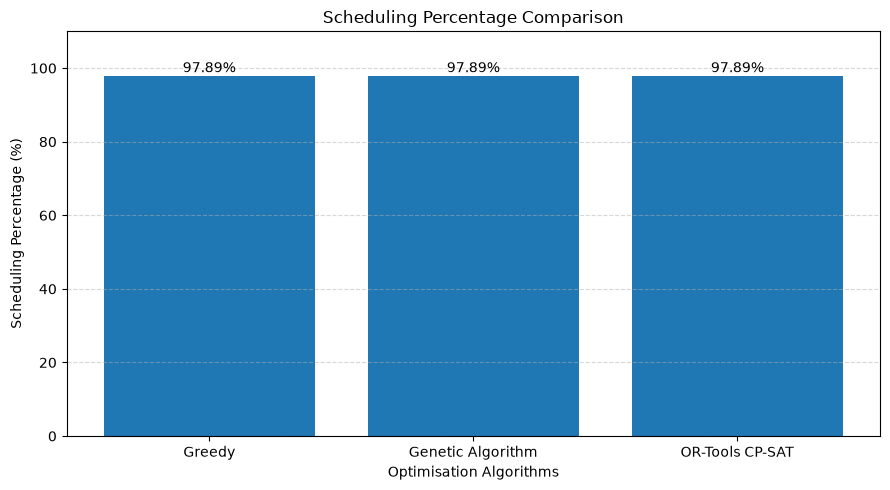

In [92]:
import matplotlib.pyplot as plt

# Algorithm names
algorithms = [
    "Greedy",
    "Genetic Algorithm",
    "OR-Tools CP-SAT"
]

# Scheduling percentages
scheduling = [97.89, 97.89, 97.89]

# Create chart
plt.figure(figsize=(9, 5))

plt.bar(algorithms, scheduling)

plt.title("Scheduling Percentage Comparison")
plt.xlabel("Optimisation Algorithms")
plt.ylabel("Scheduling Percentage (%)")

plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, value in enumerate(scheduling):
    plt.text(i, value + 1, f"{value}%", ha="center")

plt.tight_layout()
plt.show()

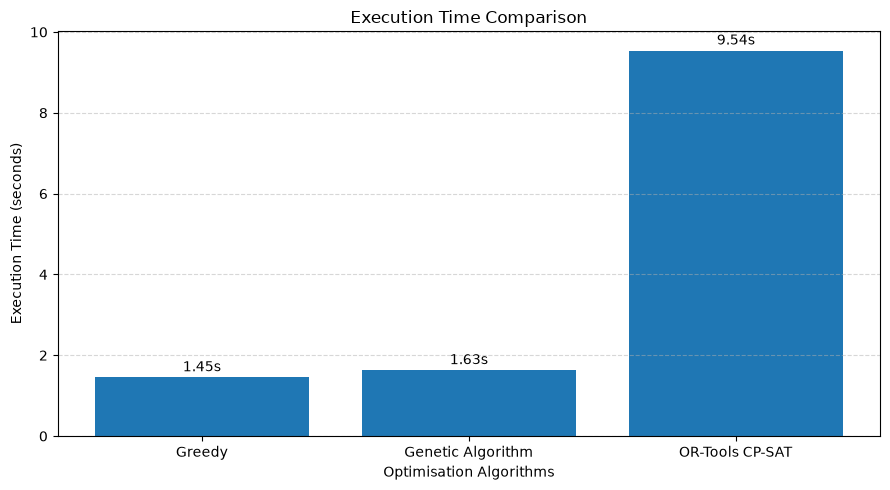

In [93]:
import matplotlib.pyplot as plt

# Algorithm names
algorithms = [
    "Greedy",
    "Genetic Algorithm",
    "OR-Tools CP-SAT"
]

# Execution times in seconds
execution_times = [
    execution_time,
    ga_execution_time,
    cp_execution_time
]

# Create chart
plt.figure(figsize=(9, 5))

plt.bar(algorithms, execution_times)

plt.title("Execution Time Comparison")
plt.xlabel("Optimisation Algorithms")
plt.ylabel("Execution Time (seconds)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, value in enumerate(execution_times):
    plt.text(i, value + 0.15, f"{value:.2f}s", ha="center")

plt.tight_layout()
plt.show()

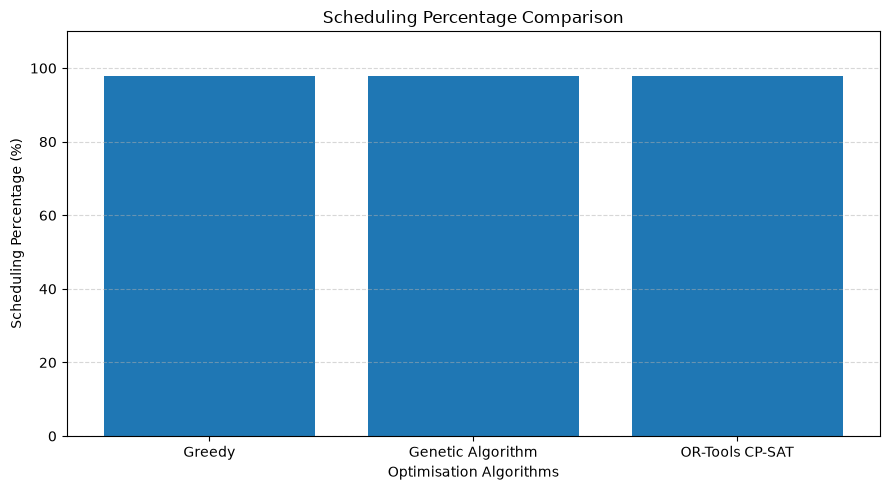

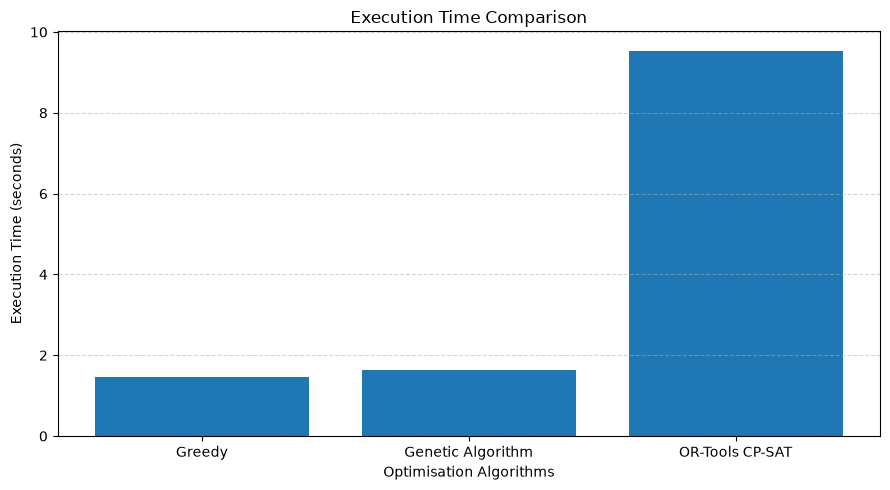

Both comparison charts saved successfully!


In [94]:
# Save scheduling percentage chart
plt.figure(figsize=(9, 5))

plt.bar(
    ["Greedy", "Genetic Algorithm", "OR-Tools CP-SAT"],
    [97.89, 97.89, 97.89]
)

plt.title("Scheduling Percentage Comparison")
plt.xlabel("Optimisation Algorithms")
plt.ylabel("Scheduling Percentage (%)")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "../reports/scheduling_comparison.png",
    dpi=300
)

plt.show()


# Save execution time chart
plt.figure(figsize=(9, 5))

plt.bar(
    ["Greedy", "Genetic Algorithm", "OR-Tools CP-SAT"],
    [execution_time, ga_execution_time, cp_execution_time]
)

plt.title("Execution Time Comparison")
plt.xlabel("Optimisation Algorithms")
plt.ylabel("Execution Time (seconds)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "../reports/execution_time_comparison.png",
    dpi=300
)

plt.show()

print("Both comparison charts saved successfully!")